Libreria que voy a usar

In [111]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from math import comb

Funcion para cargar imagenes

In [112]:
def cargarImagen(ruta):
  return cv2.imread(ruta,cv2.IMREAD_GRAYSCALE)

Funcion mostrar imagen

In [113]:
def mostrar_imagen(imagen,titulo):
  plt.imshow(imagen,cmap='gray')
  plt.axis('off')
  plt.title(titulo)

Funcion para hacer la operacion morfologica

In [114]:
def operacion_morfologica(imagen, se,funcion): # fcn es la funcion que quiero hacer. Por ej -> np.max: Dilatación, np.min: Erosión

    se_flip = np.flip(se, axis=[0,1])                                                # Espejas la matriz para hacer la convolucion en los ejes "x" e "y"
    fila,columna = se_flip.shape                                                     # Obtengo las dimensiones de la matriz
    img_pad = np.pad(imagen,((fila//2, fila//2),(columna//2,columna//2)), 'edge')    # aplico un padding a los bordes / edge=copia los valores del borde
    img_salida = np.zeros(imagen.shape)                                              # crea una imagen inicializadas en cero con la misma dimension de la imagen real

    alto, ancho = imagen.shape

    for f in range(alto):
        for c in range(ancho):
           ventana=img_pad[f:f + fila, c:c + columna]
           pixeles_relevantes = ventana[se_flip]
           resultado = funcion(pixeles_relevantes)
           img_salida[f,c] = resultado

    return img_salida


Funcion de Dilatacion

In [115]:

def dilatacion(img, se):
    return operacion_morfologica(img,se,np.max)

Funcion de Erosion

In [116]:
def erosion(img, se):
    return operacion_morfologica(img,se,np.min)

Funcion de Apertura

In [117]:
def apertura(img,se):
    return (dilatacion(erosion(img,se),se))

Funcion Cierre

In [118]:
def cierre(img,se):
    return (erosion(dilatacion(img,se),se))

Funcion borde externo

In [119]:
def borde_externo(img,se):
    return (dilatacion(img,se) - img)

Funcion borde Interno

In [120]:
def borde_interno(img,se):
    return (img - erosion(img,se))

Funcion Mediana

In [121]:
def im_mediana(img, se):
    return operacion_morfologica(img, se, np.median)

Funcion Top Hat

In [122]:
def top_hat(img,se):
    return (img - apertura(img,se))

Defino matriz estructural

In [123]:
se = np.array([[1,1,1],[1,1,1],[1,1,1]])

In [124]:
def aplicar_operacion_morfologica(funcion, cant, imagen, kernel):
    imagen_procesada = imagen
    for _ in range(cant):
        imagen_procesada = funcion(imagen_procesada, kernel)
    return imagen_procesada

------------------------------------------------------------------------------

   Muestro la imagen

In [125]:
img=cargarImagen('imagen2.jpg')
fila=2
columna=3

img_dilatada=aplicar_operacion_morfologica(dilatacion,1,img,se)
img_dilatada2 =aplicar_operacion_morfologica(dilatacion,3,img,se)

img_erosionada=aplicar_operacion_morfologica(erosion,1,img,se)
img_erosionada2 =aplicar_operacion_morfologica(erosion,3,img,se)

In [126]:
plt.figure(figsize=(15,10))

plt.subplot(fila,columna,1)
mostrar_imagen(img,'Original')
plt.subplot(fila,columna,2)
mostrar_imagen(img_dilatada,'Dilatada x1')
plt.subplot(fila,columna,3)
mostrar_imagen(img_dilatada2,'Dilatacion x3')

plt.subplot(fila,columna,4)
mostrar_imagen(img,'Original')
plt.subplot(fila,columna,5)
mostrar_imagen(img_erosionada,'Erosionada x1')
plt.subplot(fila,columna,6)
mostrar_imagen(img_erosionada2,'Erosionada x3')
plt.tight_layout()


Output hidden; open in https://colab.research.google.com to view.

In [127]:
img_apertura=aplicar_operacion_morfologica(apertura,1,img,se)
img_apertura2=aplicar_operacion_morfologica(apertura,3,img,se)

img_cierre=aplicar_operacion_morfologica(cierre,1,img,se)
img_cierre2=aplicar_operacion_morfologica(cierre,3,img,se)

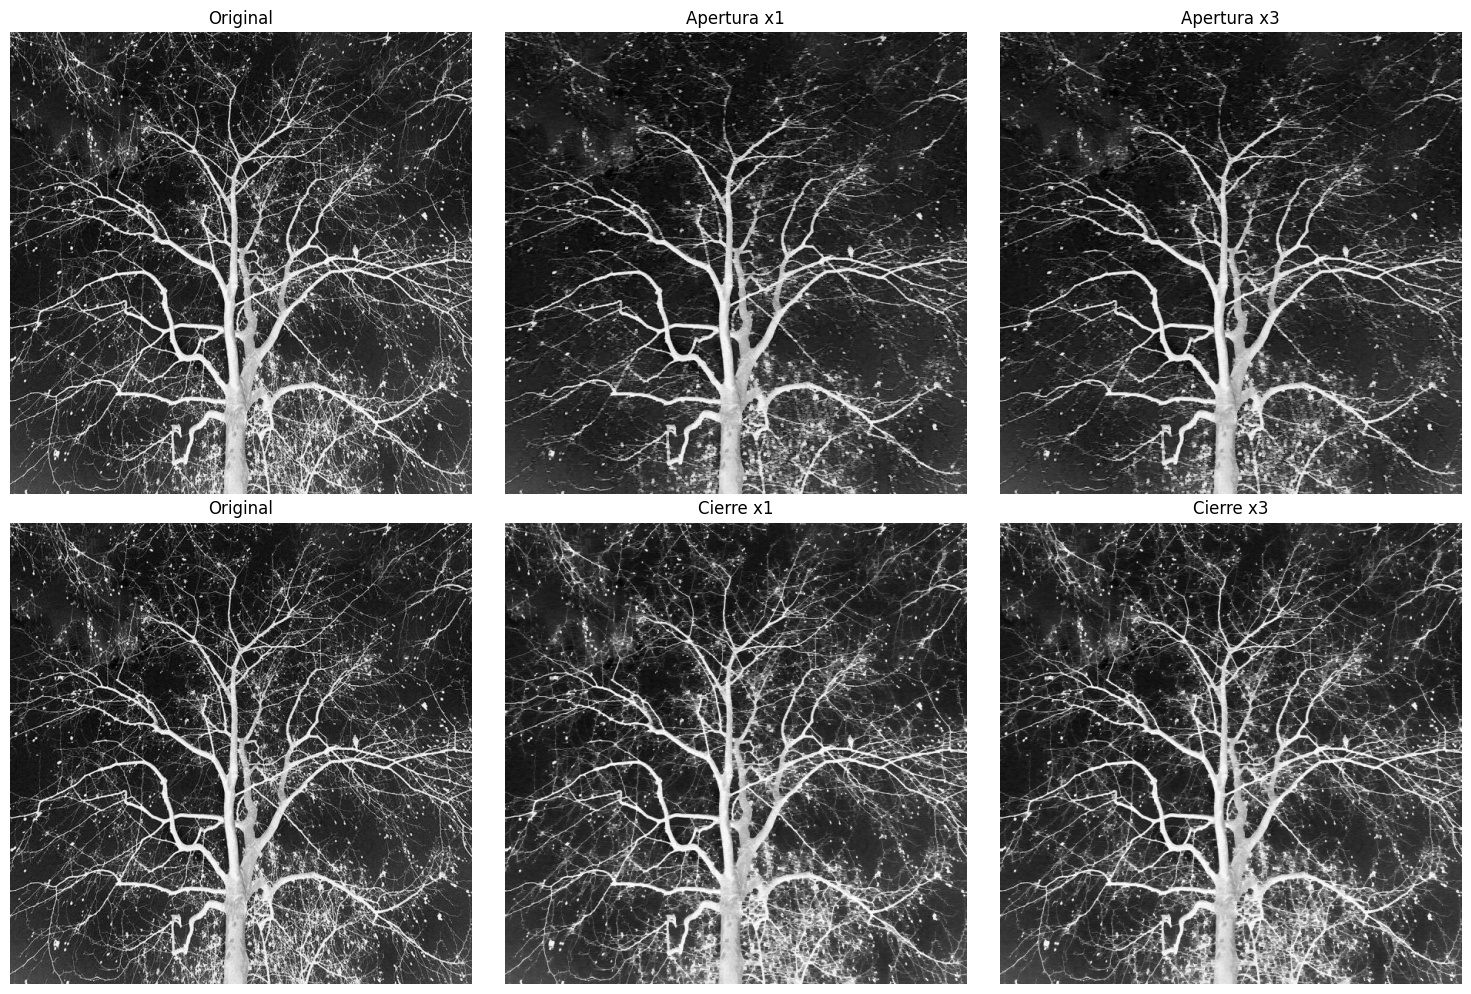

In [128]:
plt.figure(figsize=(15,10))

plt.subplot(fila,columna,1)
mostrar_imagen(img,'Original')
plt.subplot(fila,columna,2)
mostrar_imagen(img_apertura,'Apertura x1')
plt.subplot(fila,columna,3)
mostrar_imagen(img_apertura2,'Apertura x3')

plt.subplot(fila,columna,4)
mostrar_imagen(img,'Original')
plt.subplot(fila,columna,5)
mostrar_imagen(img_cierre,'Cierre x1')
plt.subplot(fila,columna,6)
mostrar_imagen(img_cierre2,'Cierre x3')
plt.tight_layout()

In [129]:
img_borde_externo=aplicar_operacion_morfologica(borde_externo,1,img,se)
img_borde_externo2=aplicar_operacion_morfologica(borde_externo,3,img,se)

img_borde_interno=aplicar_operacion_morfologica(borde_interno,1,img,se)
img_borde_interno2=aplicar_operacion_morfologica(borde_interno,3,img,se)

In [130]:
plt.figure(figsize=(15,10))

plt.subplot(fila,columna,1)
mostrar_imagen(img,'Original')
plt.subplot(fila,columna,2)
mostrar_imagen(img_borde_externo,'borde externo x1')
plt.subplot(fila,columna,3)
mostrar_imagen(img_borde_externo2,'borde externo x3')

plt.subplot(fila,columna,4)
mostrar_imagen(img,'Original')
plt.subplot(fila,columna,5)
mostrar_imagen(img_borde_interno,'Borde interno x1')
plt.subplot(fila,columna,6)
mostrar_imagen(img_borde_interno2,'Borde interno x3')
plt.tight_layout()

Output hidden; open in https://colab.research.google.com to view.

In [131]:
img_mediana=aplicar_operacion_morfologica(im_mediana,1,img,se)
img_mediana2=aplicar_operacion_morfologica(im_mediana,3,img,se)

img_top_hat=aplicar_operacion_morfologica(top_hat,1,img,se)
img_top_hat2=aplicar_operacion_morfologica(top_hat,3,img,se)

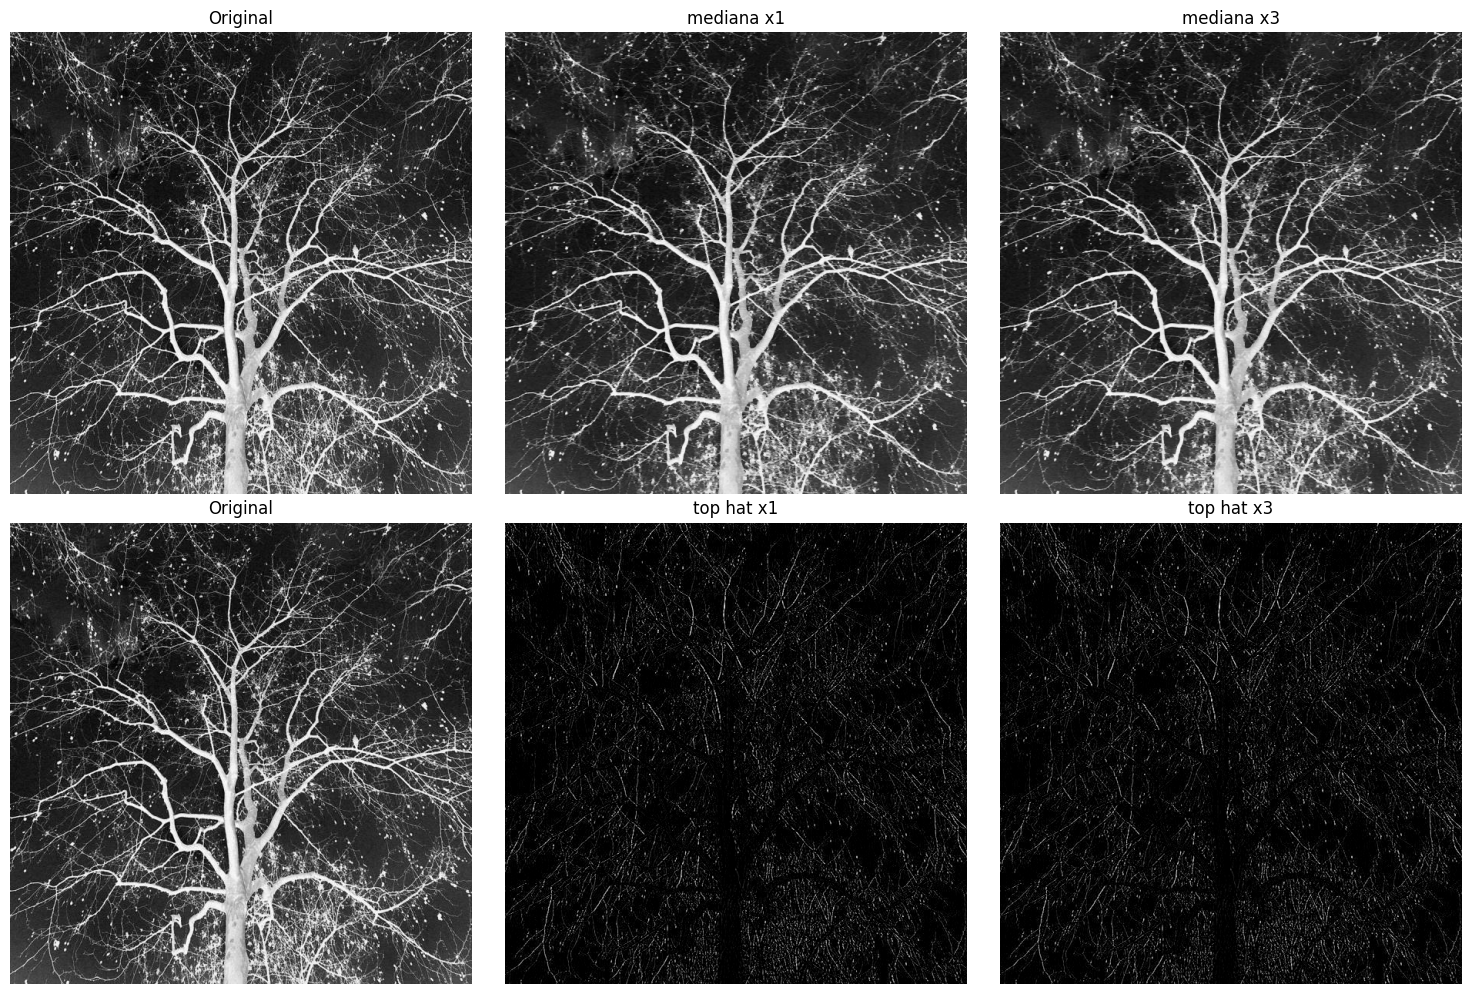

In [132]:
plt.figure(figsize=(15,10))

plt.subplot(fila,columna,1)
mostrar_imagen(img,'Original')
plt.subplot(fila,columna,2)
mostrar_imagen(img_mediana,'mediana x1')
plt.subplot(fila,columna,3)
mostrar_imagen(img_mediana2,'mediana x3')

plt.subplot(fila,columna,4)
mostrar_imagen(img,'Original')
plt.subplot(fila,columna,5)
mostrar_imagen(img_top_hat,'top hat x1')
plt.subplot(fila,columna,6)
mostrar_imagen(img_top_hat,'top hat x3')
plt.tight_layout()